# Data Visualization with Matplotlib and Seaborn
**GDG on Campus | AI/ML Team | COMSATS University, Attock Campus**
**Month 2 – Weekly Task Sheet (Week 1)**

Name: Zeenat Bibi | Reg. No: FA24-BAI-053

This notebook contains 14 tasks: 7 in Matplotlib (Part 1) and 7 in Seaborn (Part 2). Every plot is followed by a short written insight.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.rcParams['figure.dpi'] = 100

# Load all datasets (they ship with Seaborn)
tips     = sns.load_dataset("tips")
flights  = sns.load_dataset("flights")
mpg      = sns.load_dataset("mpg")
penguins = sns.load_dataset("penguins")
titanic  = sns.load_dataset("titanic")

print("Datasets loaded:", tips.shape, flights.shape, mpg.shape, penguins.shape, titanic.shape)

Datasets loaded: (244, 7) (144, 3) (398, 9) (344, 7) (891, 15)


# Part 1: Matplotlib Tasks

## Task 1: Line plot (flights)
Monthly passengers for one year (1960) with title, axis labels, markers and a grid.

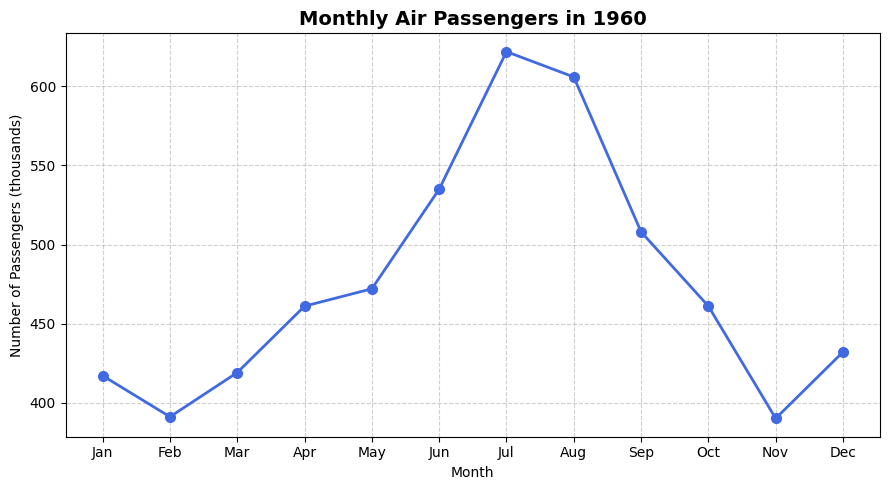

In [2]:
f1960 = flights[flights['year'] == 1960]

plt.figure(figsize=(9, 5))
plt.plot(f1960['month'].astype(str), f1960['passengers'],
         marker='o', linestyle='-', color='royalblue', linewidth=2, markersize=7)
plt.title('Monthly Air Passengers in 1960', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Passengers (thousands)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Insight:** Passenger numbers rise steadily from January and peak in July (622), then fall sharply toward November. This shows a clear seasonal pattern, with summer as the busiest travel season.

## Task 2: Bar chart (tips)
Average `total_bill` by day, with value labels on top of each bar and custom colors.

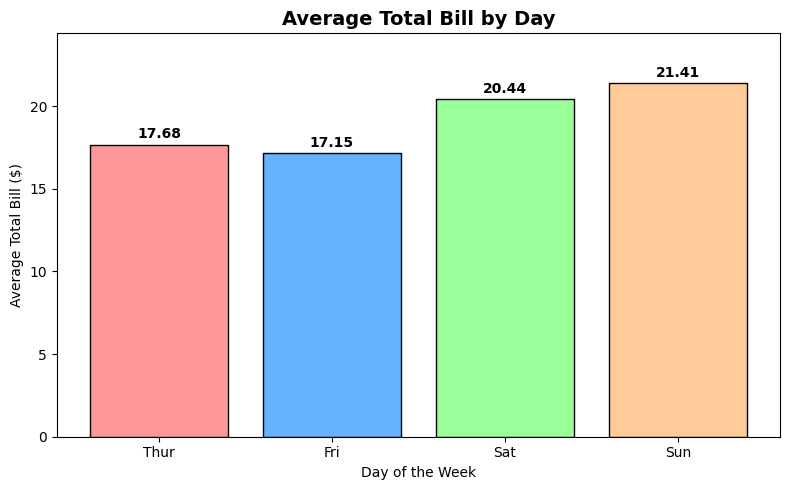

In [3]:
avg_bill = tips.groupby('day', observed=True)['total_bill'].mean()

colors = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99']
plt.figure(figsize=(8, 5))
bars = plt.bar(avg_bill.index.astype(str), avg_bill.values, color=colors, edgecolor='black')

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontweight='bold')

plt.title('Average Total Bill by Day', fontsize=14, fontweight='bold')
plt.xlabel('Day of the Week')
plt.ylabel('Average Total Bill ($)')
plt.ylim(0, avg_bill.max() + 3)
plt.tight_layout()
plt.show()

**Insight:** Weekend days have higher average bills. Sunday (about \$21.41) and Saturday (about \$20.44) are higher than Thursday and Friday (about \$17), so customers spend more when they dine out on the weekend.

## Task 3: Horizontal bar chart (mpg)
Average mpg by number of cylinders, sorted from highest to lowest.

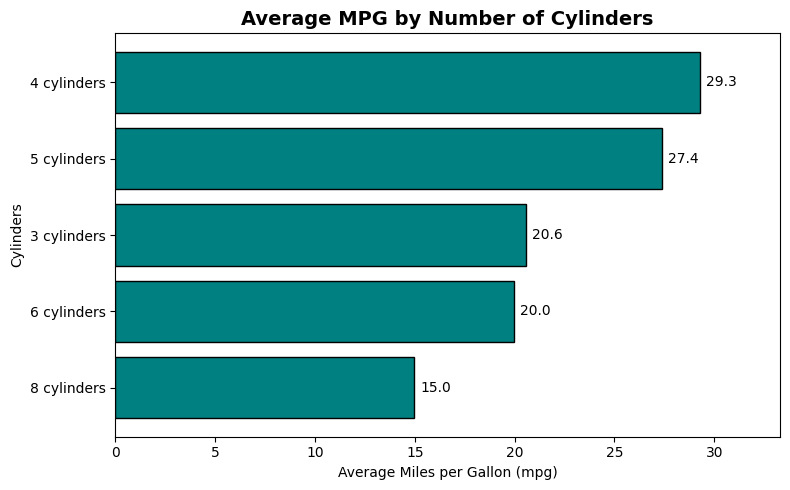

In [4]:
avg_mpg = mpg.groupby('cylinders')['mpg'].mean().sort_values(ascending=False)
labels = [f'{c} cylinders' for c in avg_mpg.index]

plt.figure(figsize=(8, 5))
# invert y-axis so the highest value appears at the top
bars = plt.barh(labels, avg_mpg.values, color='teal', edgecolor='black')
plt.gca().invert_yaxis()

for bar in bars:
    plt.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{bar.get_width():.1f}', va='center')

plt.title('Average MPG by Number of Cylinders', fontsize=14, fontweight='bold')
plt.xlabel('Average Miles per Gallon (mpg)')
plt.ylabel('Cylinders')
plt.xlim(0, avg_mpg.max() + 4)
plt.tight_layout()
plt.show()

**Insight:** 4-cylinder cars are the most fuel efficient (about 29 mpg) and 8-cylinder cars the least (about 15 mpg). The 5-cylinder group is high but has very few cars, so it should be read with caution.

## Task 4: Histogram (tips)
`total_bill` with 3 different bin sizes side by side, with vertical lines for the mean and median.

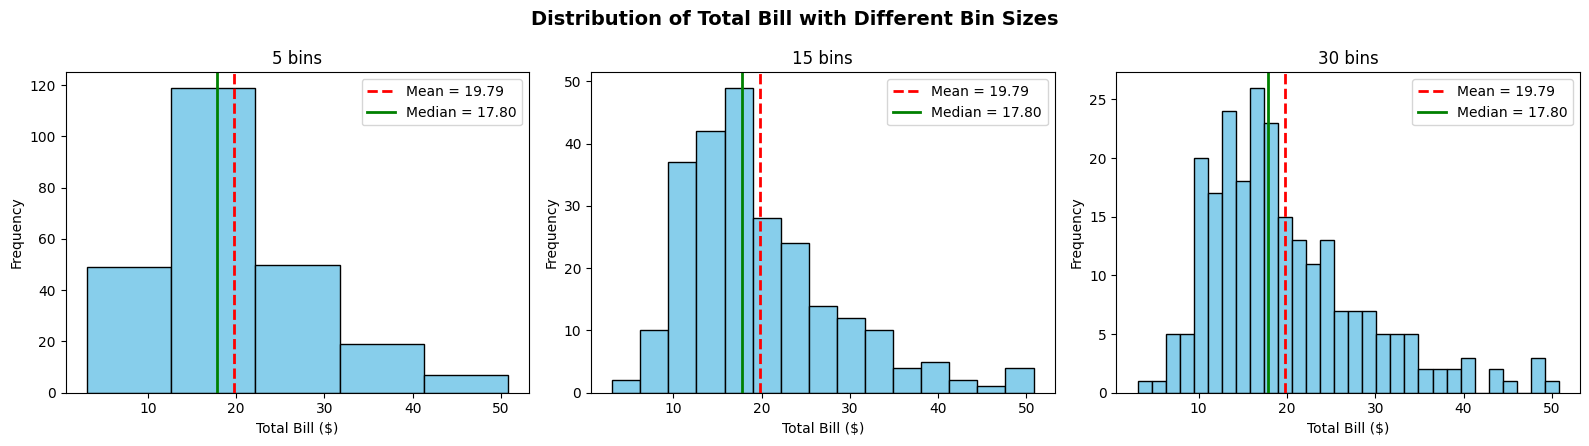

In [5]:
mean_val   = tips['total_bill'].mean()
median_val = tips['total_bill'].median()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, bins in zip(axes, [5, 15, 30]):
    ax.hist(tips['total_bill'], bins=bins, color='skyblue', edgecolor='black')
    ax.axvline(mean_val,   color='red',   linestyle='--', linewidth=2, label=f'Mean = {mean_val:.2f}')
    ax.axvline(median_val, color='green', linestyle='-',  linewidth=2, label=f'Median = {median_val:.2f}')
    ax.set_title(f'{bins} bins')
    ax.set_xlabel('Total Bill ($)')
    ax.set_ylabel('Frequency')
    ax.legend()

fig.suptitle('Distribution of Total Bill with Different Bin Sizes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight:** The distribution is right-skewed: most bills are between \$10 and \$25 and a few are very large. The mean (19.79) is higher than the median (17.80), which confirms the skew. Too few bins hide the shape, and too many make it noisy, so 15 bins looks like a good balance.

## Task 5: Scatter plot (mpg)
Weight vs mpg, color by origin, point size by horsepower, with a legend.

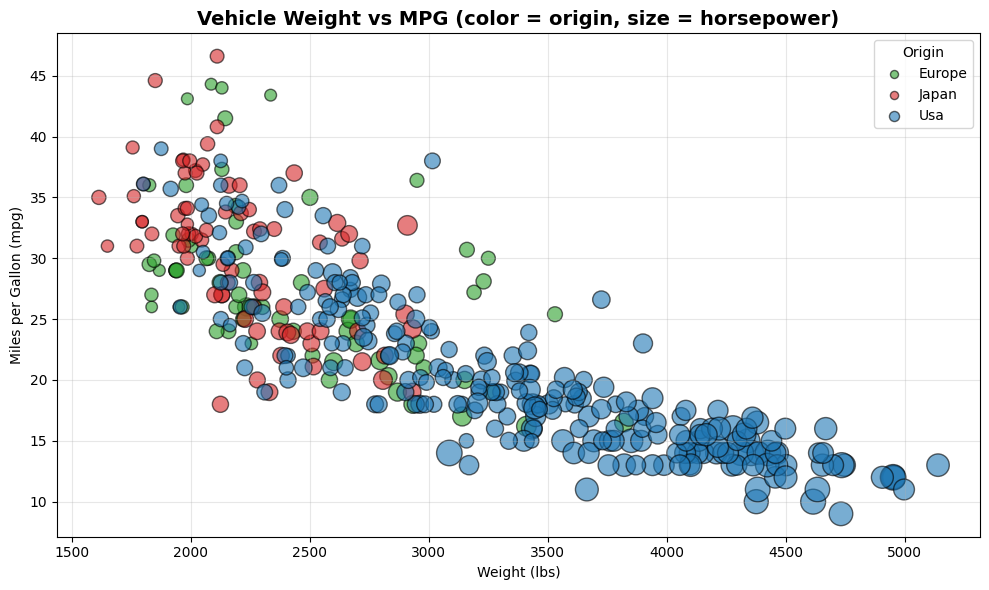

In [6]:
df = mpg.dropna(subset=['horsepower', 'weight', 'mpg'])
color_map = {'usa': 'tab:blue', 'europe': 'tab:green', 'japan': 'tab:red'}

plt.figure(figsize=(10, 6))
for origin, grp in df.groupby('origin'):
    plt.scatter(grp['weight'], grp['mpg'],
                s=grp['horsepower'] * 1.5,   # size by horsepower
                c=color_map[origin], alpha=0.6, edgecolor='k', label=origin.title())

plt.title('Vehicle Weight vs MPG (color = origin, size = horsepower)', fontsize=14, fontweight='bold')
plt.xlabel('Weight (lbs)')
plt.ylabel('Miles per Gallon (mpg)')
plt.legend(title='Origin', markerscale=0.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:** There is a strong negative relationship: heavier cars get lower mpg. Large bubbles (high horsepower) sit at the heavy, low-mpg end. Japanese and European cars are lighter with better mpg, while American cars dominate the heavy end.

## Task 6: Pie / donut chart (tips)
Smoker vs non-smoker share with percentage labels.

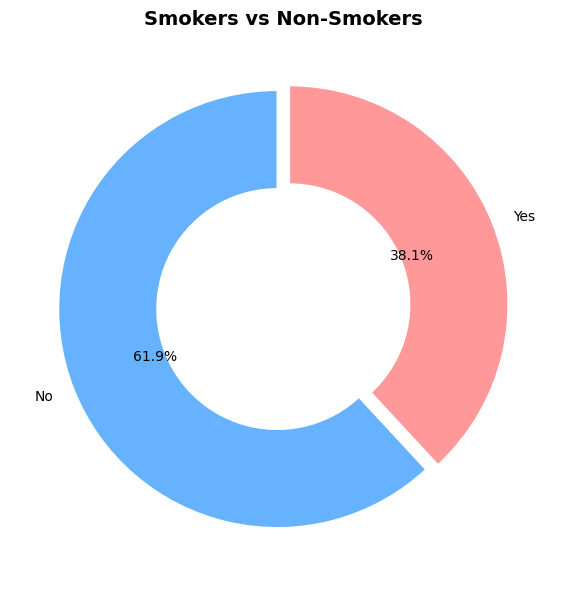

In [7]:
smoker_counts = tips['smoker'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(smoker_counts.values, labels=smoker_counts.index, autopct='%1.1f%%',
        startangle=90, colors=['#66B2FF', '#FF9999'], explode=(0.03, 0.03),
        wedgeprops={'width': 0.45, 'edgecolor': 'white'})   # width makes it a donut
plt.title('Smokers vs Non-Smokers', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight:** About 62% of the parties are non-smokers and about 38% are smokers, so non-smoking customers are the clear majority in this dataset.

## Task 7: Mini dashboard (2 x 2 subplots)
Four of the plots above combined in one figure, saved as PNG at dpi=300.

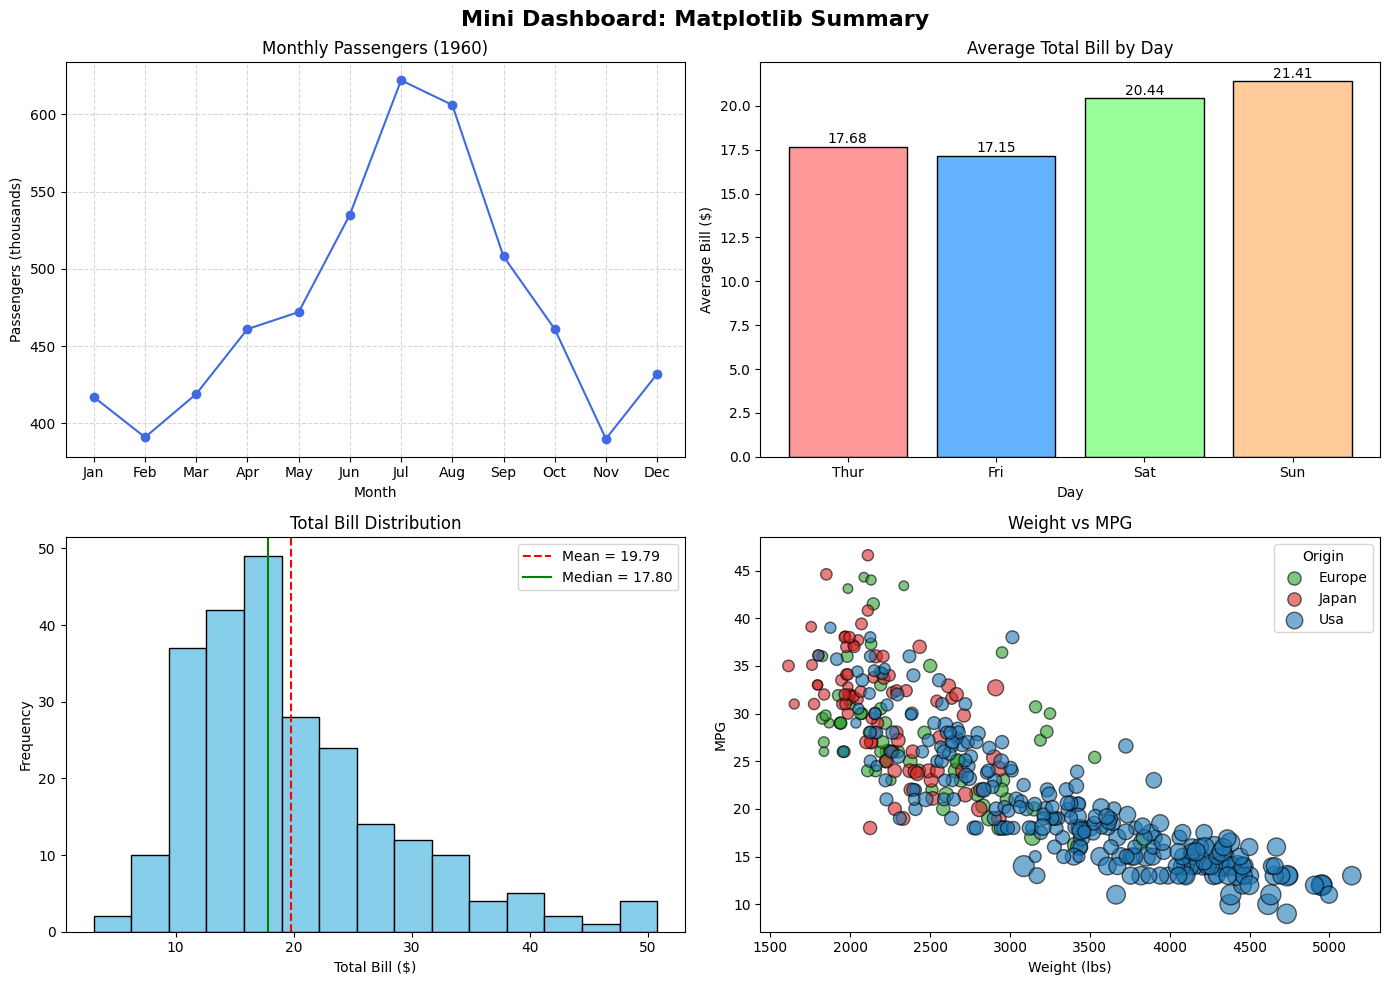

Saved as mini_dashboard.png (dpi=300)


In [8]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# (0,0) Line plot - flights 1960
axs[0, 0].plot(f1960['month'].astype(str), f1960['passengers'], marker='o', color='royalblue')
axs[0, 0].set_title('Monthly Passengers (1960)')
axs[0, 0].set_xlabel('Month'); axs[0, 0].set_ylabel('Passengers (thousands)')
axs[0, 0].grid(True, linestyle='--', alpha=0.5)

# (0,1) Bar chart - avg bill by day
b = axs[0, 1].bar(avg_bill.index.astype(str), avg_bill.values, color=colors, edgecolor='black')
for bar in b:
    axs[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                   f'{bar.get_height():.2f}', ha='center')
axs[0, 1].set_title('Average Total Bill by Day')
axs[0, 1].set_xlabel('Day'); axs[0, 1].set_ylabel('Average Bill ($)')

# (1,0) Histogram - total bill
axs[1, 0].hist(tips['total_bill'], bins=15, color='skyblue', edgecolor='black')
axs[1, 0].axvline(mean_val, color='red', linestyle='--', label=f'Mean = {mean_val:.2f}')
axs[1, 0].axvline(median_val, color='green', label=f'Median = {median_val:.2f}')
axs[1, 0].set_title('Total Bill Distribution')
axs[1, 0].set_xlabel('Total Bill ($)'); axs[1, 0].set_ylabel('Frequency')
axs[1, 0].legend()

# (1,1) Scatter - weight vs mpg
for origin, grp in df.groupby('origin'):
    axs[1, 1].scatter(grp['weight'], grp['mpg'], s=grp['horsepower'], c=color_map[origin],
                      alpha=0.6, edgecolor='k', label=origin.title())
axs[1, 1].set_title('Weight vs MPG')
axs[1, 1].set_xlabel('Weight (lbs)'); axs[1, 1].set_ylabel('MPG')
axs[1, 1].legend(title='Origin')

fig.suptitle('Mini Dashboard: Matplotlib Summary', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('mini_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved as mini_dashboard.png (dpi=300)")

**Insight:** The dashboard shows four views in one place: seasonality in air travel, higher weekend spending, a right-skewed bill distribution, and the weight vs fuel-efficiency trade-off. Combining plots makes it easy to compare different patterns at a glance.

# Part 2: Seaborn Tasks

## Task 1: Countplot (titanic)
Passengers by class with `hue='sex'`.

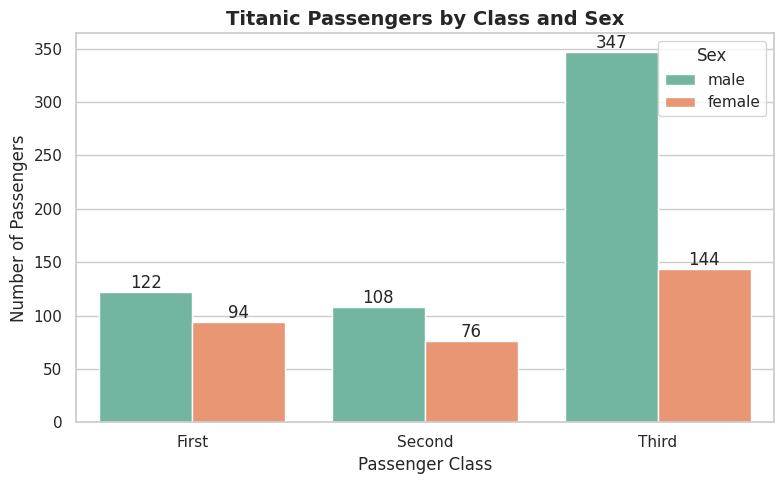

In [9]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=titanic, x='class', hue='sex', palette='Set2')
for container in ax.containers:
    ax.bar_label(container)
plt.title('Titanic Passengers by Class and Sex', fontsize=14, fontweight='bold')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.legend(title='Sex')
plt.tight_layout()
plt.show()

**Insight:** Third class had by far the most passengers, and it was strongly male-dominated (347 men vs 144 women). First and second class were much smaller and more balanced.

## Task 2: Histogram with KDE (penguins)
`flipper_length_mm` for each species using `histplot(kde=True)`.

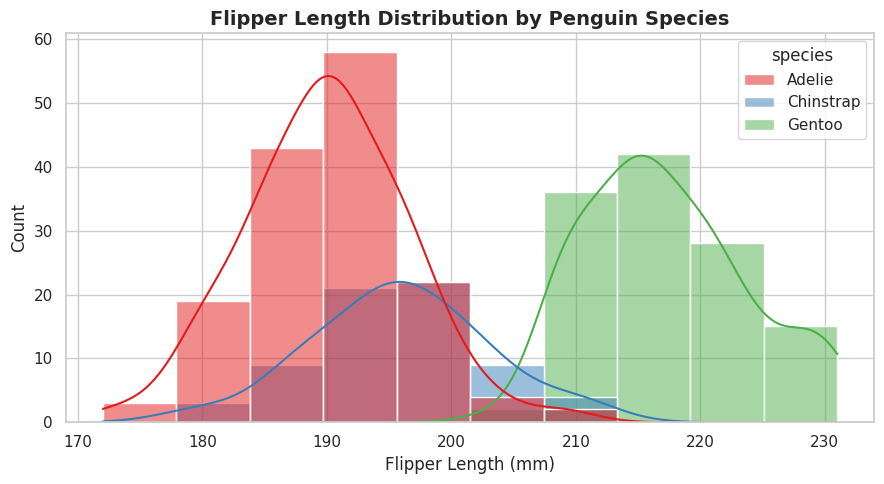

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(data=penguins, x='flipper_length_mm', hue='species', kde=True, palette='Set1', alpha=0.5)
plt.title('Flipper Length Distribution by Penguin Species', fontsize=14, fontweight='bold')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

**Insight:** Gentoo penguins have clearly longer flippers (around 217 mm on average) with little overlap. Adelie (about 190 mm) and Chinstrap (about 196 mm) overlap heavily, so flipper length separates Gentoo easily but not the other two.

## Task 3: Box plot vs violin plot (penguins)
`body_mass_g` by species with both plot types side by side.

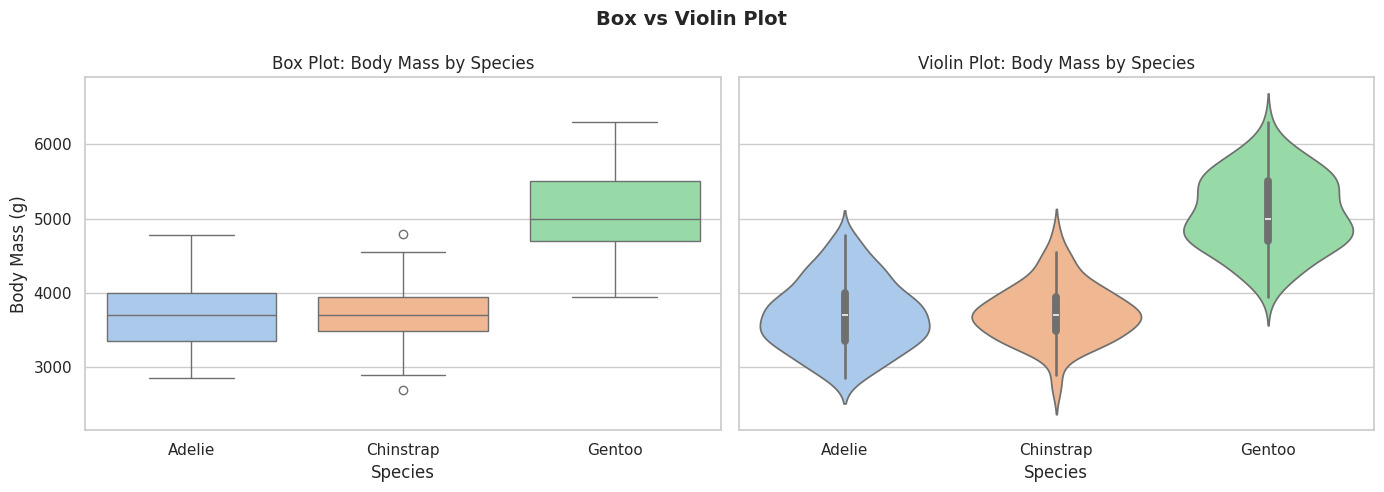

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.boxplot(data=penguins, x='species', y='body_mass_g', hue='species', palette='pastel', legend=False, ax=axes[0])
axes[0].set_title('Box Plot: Body Mass by Species')
axes[0].set_xlabel('Species'); axes[0].set_ylabel('Body Mass (g)')

sns.violinplot(data=penguins, x='species', y='body_mass_g', hue='species', palette='pastel', legend=False, ax=axes[1])
axes[1].set_title('Violin Plot: Body Mass by Species')
axes[1].set_xlabel('Species'); axes[1].set_ylabel('')

fig.suptitle('Box vs Violin Plot', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight (2 lines):** The box plot summarizes the median, quartiles and outliers, which makes it good for quick comparison. The violin plot shows more because it also reveals the full shape of the distribution (spread, skew and multiple peaks), where the box plot hides it. In both, Gentoo is clearly heavier (about 5,076 g) than Adelie and Chinstrap (about 3,700 g).

## Task 4: Scatterplot (penguins)
`bill_length_mm` vs `bill_depth_mm` with `hue='species'` and `style='sex'`.

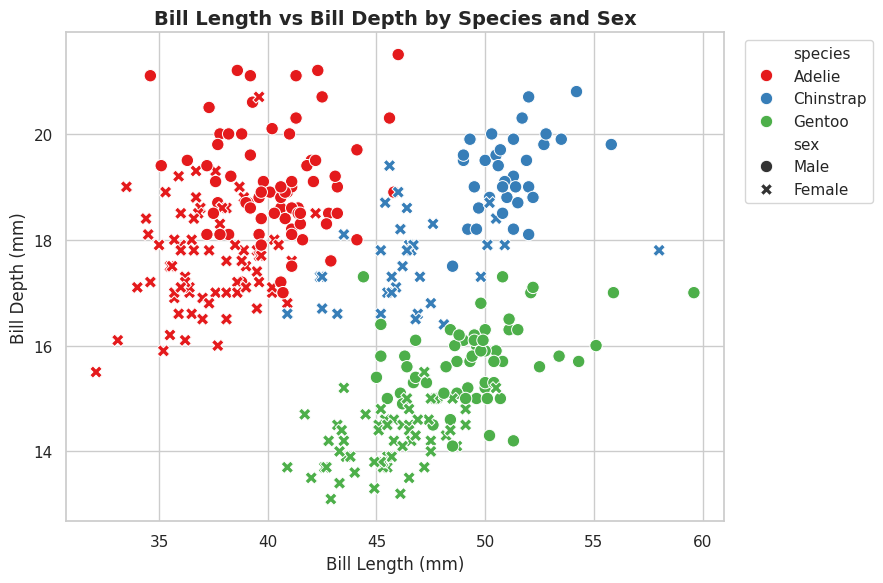

In [12]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm',
                hue='species', style='sex', s=80, palette='Set1')
plt.title('Bill Length vs Bill Depth by Species and Sex', fontsize=14, fontweight='bold')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Bill Depth (mm)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Insight:** The three species form separate clusters. Gentoo have long, shallow bills (low depth), Adelie have short, deep bills, and Chinstrap have long, deep bills. Within each species, males have larger bills than females.

## Task 5: Heatmap (penguins)
Correlation matrix of the numeric columns with `annot=True` and a diverging colormap.

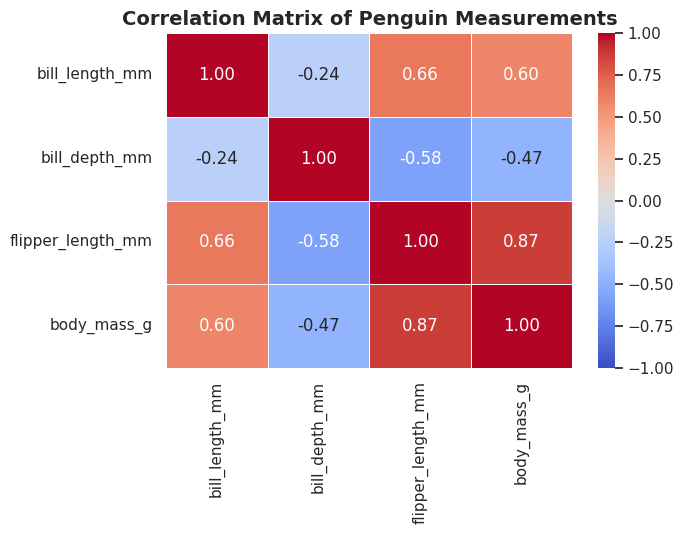

In [13]:
corr = penguins.select_dtypes(include='number').corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Penguin Measurements', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight:** Flipper length and body mass have the strongest positive correlation (0.87), so bigger flippers go with heavier penguins. Bill depth is negatively correlated with flipper length and body mass, which is partly because Gentoo penguins have shallow bills but large bodies.

## Task 6: Pairplot (penguins)
`pairplot` with `hue='species'`, followed by 3 insights.

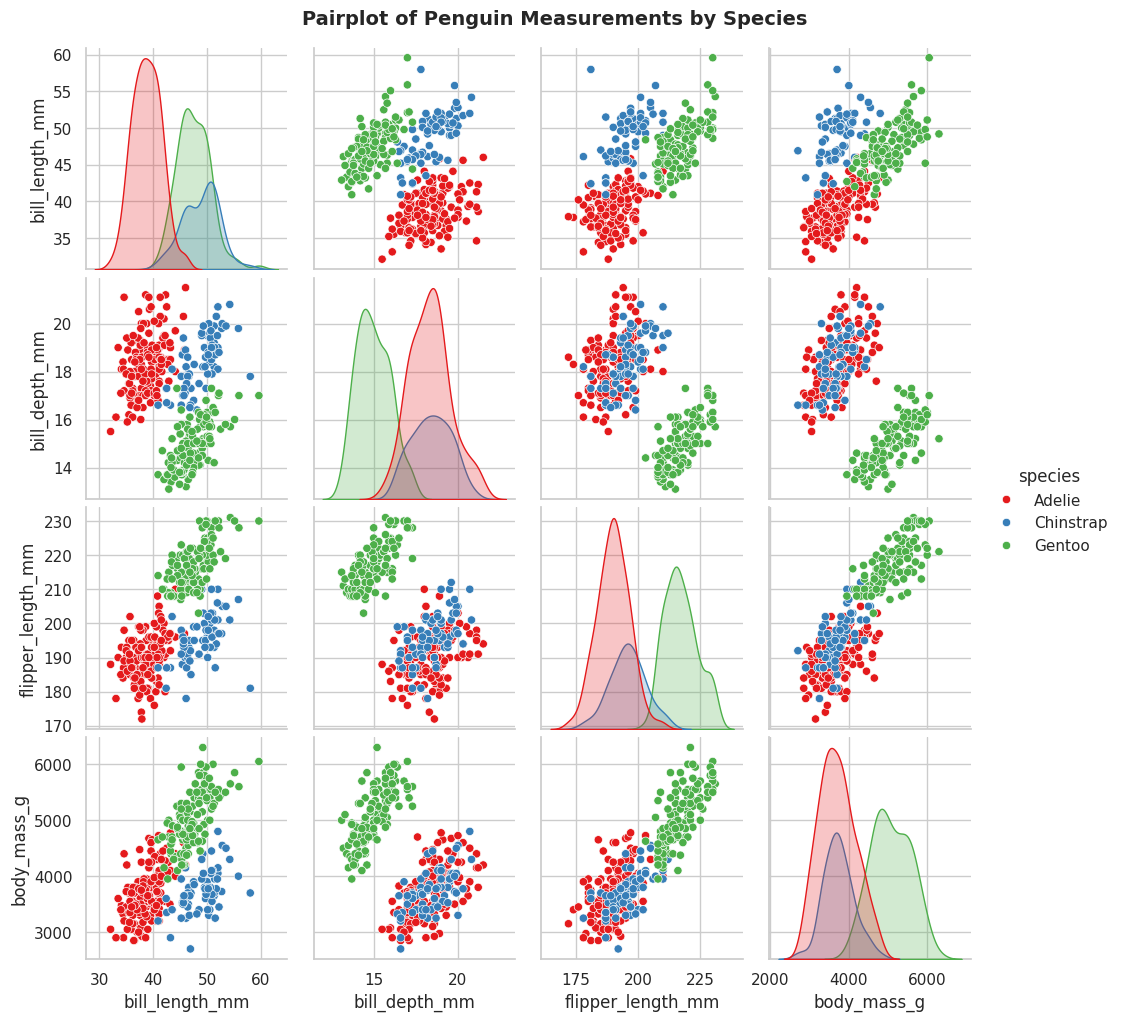

In [14]:
g = sns.pairplot(penguins, hue='species', palette='Set1', diag_kind='kde', corner=False)
g.fig.suptitle('Pairplot of Penguin Measurements by Species', y=1.02, fontsize=14, fontweight='bold')
plt.show()

**3 Insights from the pairplot:**
1. **Gentoo is the most distinct species.** It is clearly separated from the others in body mass and flipper length, so these two features are the easiest way to identify it.
2. **Adelie and Chinstrap overlap** in flipper length and body mass, but they separate when bill length and bill depth are combined (Chinstrap has longer bills).
3. **Overall trends reverse inside species.** Across all penguins bill depth looks negatively related to bill length, but within each species the relationship is positive. This is an example of Simpson's paradox, so always look at groups separately.

## Task 7: lmplot / FacetGrid (tips)
`total_bill` vs `tip` with a regression line, split by `time` and `smoker`, with a custom theme via `sns.set_theme()`.

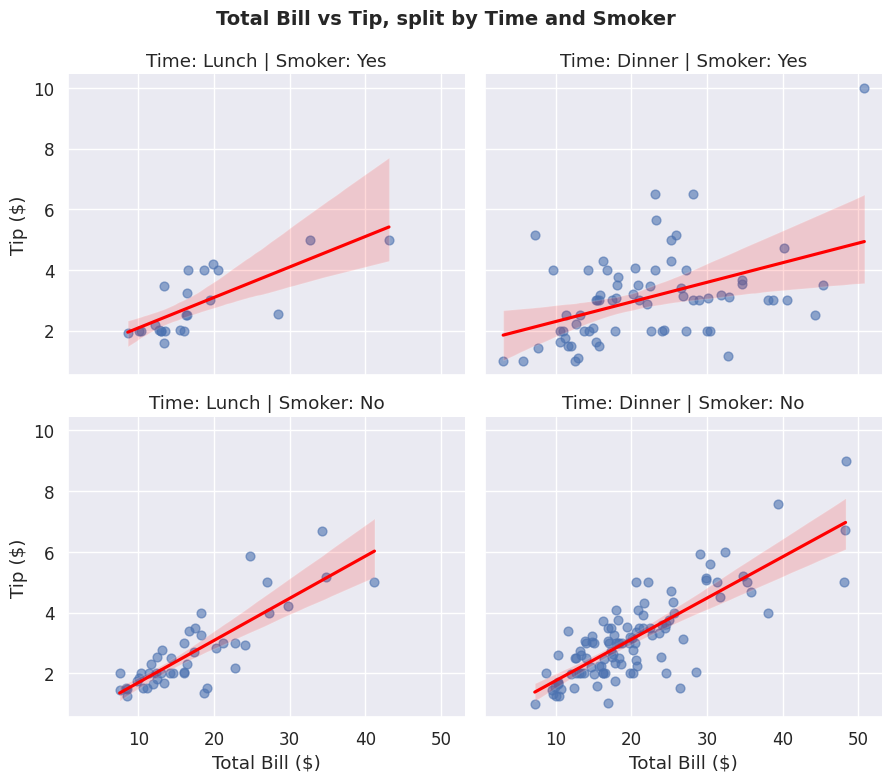

In [15]:
# Custom theme
sns.set_theme(style='darkgrid', palette='deep', font_scale=1.1)

g = sns.lmplot(data=tips, x='total_bill', y='tip', col='time', row='smoker',
               height=3.8, aspect=1.2,
               scatter_kws={'alpha': 0.6, 's': 40}, line_kws={'color': 'red'})
g.set_axis_labels('Total Bill ($)', 'Tip ($)')
g.set_titles('Time: {col_name} | Smoker: {row_name}')
g.fig.suptitle('Total Bill vs Tip, split by Time and Smoker', y=1.03, fontsize=14, fontweight='bold')
plt.show()

**Insight:** In every group the tip increases with the total bill (a positive linear relationship). Dinner has many more data points than lunch, and the slope and spread differ by group; smoker lunch has very few points, so its trend is less reliable.